In [80]:
# --- Routing Workflow ---
# LLM decides which path to take based on user input:
#   - 'history' -> generate_history only
#   - 'accomplishment' -> generate_achievements only
#   - 'article' -> full parallel pipeline (history + achievements -> article -> refined)
from typing import Annotated, List, Literal, Optional, TypedDict,NotRequired
from pydantic import BaseModel, Field, field_validator, ValidationError
from operator import add
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END, START
from langgraph.graph.state import CompiledStateGraph
from IPython.display import Image, display
import re

# Google
from langchain_google_genai import ChatGoogleGenerativeAI

# HuggingFace
# from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
# from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

# Cohere
from langchain_cohere import CohereEmbeddings

# Prompts
from langchain.prompts import PromptTemplate
from langchain_core.messages import BaseMessage
from langchain_core.tools import tool

# Others
import os
from dotenv import load_dotenv
# # LangSmith
# import uuid
# from langchain_core.tracers.context import collect_runs
# from langchain_core.tracers.langchain import wait_for_all_tracers
# from langsmith import Client
# from langchain.callbacks.tracers import LangChainTracer

In [81]:
from dotenv import load_dotenv

# Provide the filename as a string
load_dotenv('.env')

True

In [82]:
# loadding Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

## **Pydantic: Validation Logic for Routing**

In [83]:
class Route(BaseModel):
    step: Literal["history", "accomplishment","article"] = Field(
        description="The next step of the workflow process."
    )

In [84]:
router = google_llm.with_structured_output(Route)

## **Pydantic: Validation Logic for each node**

In [85]:
# Pydantic: Validate external input
class ScientistInput(BaseModel):
    scientist: str = Field( min_length=3,max_length=100, 
    description="The name of the scientist"
    )

    @field_validator("scientist")
    def validate_scientist(cls, value):
        value = value.strip()
        if not re.search("[a-zA-Z]", value):
            raise ValueError("Scientist name must contain letters.")
        return value.strip()

In [86]:
# Pydantic: Validate LLM outputs
class ScientistHistoryOutput(BaseModel):
    history: str = Field(description="The history of the scientist")

class ScientistAchievementsOutput(BaseModel):
    achievements: list[str] = Field(description="Five major achievements of the scientist")

class ScientistArticleOutput(BaseModel):
    article: str = Field(description="Detailed article about the scientist")

class RefinedArticleOutput(BaseModel):
    refined_article: str = Field(description="Refined article about the scientist under 1000 words")

In [87]:
# Structured LLMs 
history_llm = google_llm.with_structured_output(ScientistHistoryOutput)
achievements_llm = google_llm.with_structured_output(ScientistAchievementsOutput)
article_llm = google_llm.with_structured_output(ScientistArticleOutput)
refined_article_llm = google_llm.with_structured_output(RefinedArticleOutput)

## **Define Graph State**

In [88]:
# Graph State
class State(TypedDict):
    # For routing
    input: str
    decision: NotRequired[str]
    scientist: NotRequired[str]
    history: NotRequired[str]
    achievements: NotRequired[list[str]]
    article: NotRequired[str]
    refined_article: NotRequired[str] # or NotRequired[Optional[str]]

## **Defining the Nodes**

In [89]:
# Defining the nodes
def generate_history(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    "Provide a brief history of {scientist}."
    )
    
    scientist = {"scientist": state["scientist"]}
    history_chain = prompt | history_llm
    response = history_chain.invoke(scientist) # or  response: ScientistHistoryOutput = history_chain.invoke(scientist)

    # Returning the response as a dictionary with the key "history"
    # return {"history": response.content}
    # changes to this due to structured output, we can access the history attribute directly
    return {"history": response.history}

In [90]:
# Defining the nodes
def generate_achievements(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    """Provide 5 top achievements of {scientist} in bullet points.
    Example:
    - Achievement 1
    - Achievement 2
    - Achievement 3
    - Achievement 4
    - Achievement 5
    """
    )
    
    scientist = {"scientist": state["scientist"]}
    achievement_chain = prompt | achievements_llm
    response = achievement_chain.invoke(scientist)

    achievements_list_text = "\n".join([
        f"- {achievement}" for achievement in response.achievements
    ])
    return {"achievements": achievements_list_text}

In [ ]:
# Defining the nodes
def generate_article(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    """Provide an in depth article about {scientist} based on the following information:
    History: {history}
    Achievements: {achievements}
    Final Article must be in Markdown format with different sections. For example;
    ## **Title**

    ### **History**

    ### **Achievements**

    ### **Main Contributions**

    ## **Conclusion**

    This is just an example you can modify
    You must give the article in Markdown format
    """
    )
    
    information_data = {"scientist": state["scientist"], 
                        "history": state["history"], 
                        "achievements": state["achievements"] 
                        }
    article_chain = prompt | article_llm
    response = article_chain.invoke(information_data)

    # Returning the response as a dictionary with the key "article"
    return {"article": response.article}

In [ ]:
# Defining the nodes
def generate_refined_article(state:State):
    # Prompt to get the scientist's information
    # Safely retrieve 'article' using .get() to prevent KeyError
    generated_article = state.get("article", "")
    
    if not generated_article:
        return {"refined_article": "Error: Article was not generated properly."}

    article_length = len(generated_article.split())
    if article_length > 1000:
        prompt = PromptTemplate.from_template(
        """Summarise the following article about {scientist} in less than 1000 words from given article\n{article}.\n
        It should be concise and clear, and should not lose the main points of the article.
        Final Article must be in Markdown format with different sections. For example;
        ## **Title**

        ### **History**

        ### **Achievements**

        ### **Main Contributions**

        ## **Conclusion**

        This is just an example you can modify
        You must give the article in Markdown format
        """
        )
        refined_article_data = {"scientist": state["scientist"], "article": generated_article}
        refined_article_chain = prompt | refined_article_llm
        response = refined_article_chain.invoke(refined_article_data)

        # Returning the response as a dictionary with the key "refined_article"
        return {"refined_article": response.refined_article}
    else:
        print("Initial article is already under 1000 words. No refinement needed.")
        return {"refined_article": generated_article}

In [114]:
# LLM classifies input into one of the predefined route categories
def llm_routing(state: State):
    prompt = PromptTemplate.from_template(
    """Route the workflow based on the input provided by the user. 
    - If the input is asking for a history of a scientist, route to 'history'. 
    - If the input is asking for achievements of a scientist, route to 'accomplishment'. 
    - If the input is asking for an article about a scientist, route to 'article'. Especially if the input is asking for both history and achievements, route to 'article'.
    The input is: {input}.
    """
    )

    router_data  = {"input": state["input"]}
    router_chain  = prompt | router
    decision = router_chain.invoke(router_data)

    return {"decision": decision.step}

In [115]:
# Maps LLM decision string to next node name
def route_decision(state:State):
    decision = state.get("decision", "")
    if decision == "history":
        return "generate_history"
    elif decision == "accomplishment":
        return "generate_achievements"
    elif decision == "article":
        return "article_workflow"
    raise ValueError(f"Invalid decision: {decision}")

In [116]:
# Extracts the scientist's name from the user input via LLM
def scientist_name_extraction(state:State):
    # Extract the scientist's name from the input
    prompt = PromptTemplate.from_template(
    """Extract the scientist's name from the input provided by the user. 
    The input is: {input}.
    """
    )

    extraction_data  = {"input": state["input"]}
    extraction_chain  = prompt | google_llm
    response = extraction_chain.invoke(extraction_data)

    try:
        validated = ScientistInput.model_validate(
                    {
                    "scientist": response.content.strip()
                    }
        )
        # Assuming the response contains the extracted name in a field called 'content'
        return {"scientist": validated.scientist}

    except ValidationError as e:
        print(e.errors()[0]["msg"])

## **Building the Graph**

In [117]:
# Builds a subgraph for the 'article' route: history + achievements in parallel, then article, then refine
def build_article_workflow():
    article_workflow = StateGraph(State)
    article_workflow.add_node("generate_history", generate_history)
    article_workflow.add_node("generate_achievements", generate_achievements)
    article_workflow.add_node("generate_article", generate_article)
    article_workflow.add_node("generate_refined_article", generate_refined_article)

    # start both in parallel
    article_workflow.add_edge(START, "generate_history")
    article_workflow.add_edge(START, "generate_achievements")
    article_workflow.add_edge("generate_history", "generate_article")
    article_workflow.add_edge("generate_achievements", "generate_article")
    article_workflow.add_edge("generate_article", "generate_refined_article")
    article_workflow.add_edge("generate_refined_article", END)

    return article_workflow.compile()
    
        

In [118]:
# Builds the main graph with extraction -> routing -> conditional edges
def build_main_graph():    
    workflow = StateGraph(State)

    # Build article subgraph
    article_workflow = build_article_workflow()

    # Registering the nodes
    workflow.add_node("scientist_name_extraction", scientist_name_extraction)
    workflow.add_node("generate_history", generate_history)
    workflow.add_node("generate_achievements", generate_achievements)
    workflow.add_node("article_workflow", article_workflow)
    workflow.add_node("llm_routing", llm_routing)

    # START
    workflow.add_edge(START, "scientist_name_extraction")
    workflow.add_edge("scientist_name_extraction", "llm_routing")

    # ROUTING LOGIC
    workflow.add_conditional_edges(
        "llm_routing", route_decision,
    {
        # name returned by route_decision function: name of the next node to execute
        "generate_history": "generate_history",
        "generate_achievements": "generate_achievements",
        "article_workflow": "article_workflow",
    }
    )

    # SIMPLE ROUTES
    workflow.add_edge("generate_history", END)
    workflow.add_edge("generate_achievements", END)
    workflow.add_edge("article_workflow", END)

    return workflow.compile()

In [119]:
graph = build_main_graph()
article_workflow = build_article_workflow()

In [120]:
# Renders the LangGraph workflow as a Mermaid diagram
def graph_visualiser(graph):
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print(e)

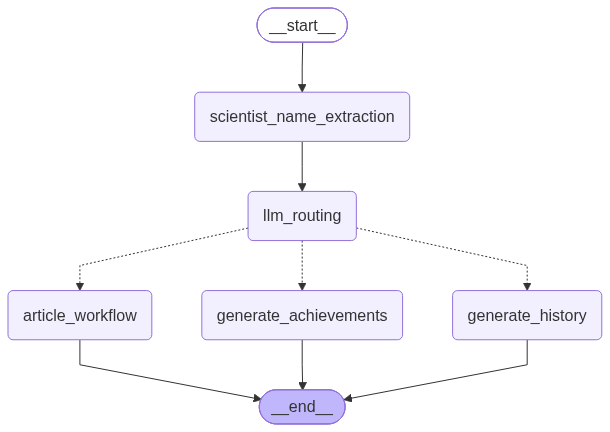

In [121]:
graph_visualiser(graph)

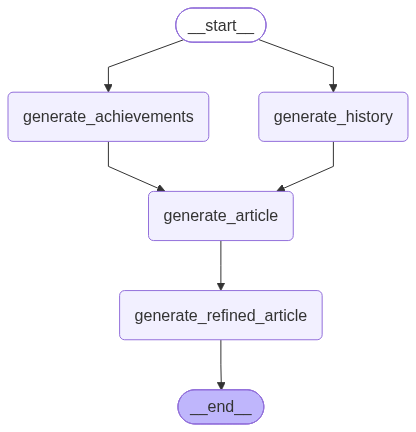

In [122]:
# article_workflow
graph_visualiser(article_workflow)

In [123]:
# Example usage
results = graph.invoke(
    {
        "input": "Tell me about Albert Einstein's history",
    }
)

In [124]:
results

{'input': "Tell me about Albert Einstein's history",
 'decision': 'history',
 'scientist': 'Albert Einstein',
 'history': 'Albert Einstein was a German-born theoretical physicist who developed the theory of relativity, one of the two pillars of modern physics. His work is also known for its influence on the philosophy of science. He is best known by the general public for his mass–energy equivalence formula E = mc², which has been dubbed "the world\'s most famous equation". He received the Nobel Prize in Physics in 1921 for his "services to theoretical physics, and especially for his discovery of the law of the photoelectric effect", a pivotal step in the evolution of quantum theory.'}

In [125]:
# Example usage
results = graph.invoke(
    {
        "input": "Tell me about Albert Einstein's achievements",
    }
)

In [126]:
results

{'input': "Tell me about Albert Einstein's achievements",
 'decision': 'accomplishment',
 'scientist': 'Albert Einstein',
 'achievements': "- Developed the theory of relativity, one of the two pillars of modern physics.\n- Discovered the law of the photoelectric effect, for which he was awarded the Nobel Prize in Physics in 1921.\n- Made significant contributions to quantum theory, including the concept of light quanta (photons).\n- Developed the mass-energy equivalence formula, E=mc², which is the world's most famous equation.\n- Proposed the theory of Brownian motion, which provided strong evidence for the existence of atoms and molecules."}

In [127]:
results = graph.invoke(
    {
        "input": "Give me an article about Albert Einstein",
    }
)

Initial article is already under 1000 words. No refinement needed.


In [113]:
results

{'input': 'Give me an article about Albert Einstein',
 'decision': 'article',
 'scientist': 'Albert Einstein',
 'history': 'Albert Einstein was a German-born theoretical physicist who developed the theory of relativity, one of the two pillars of modern physics. His work is also known for its influence on the philosophy of science. He is best known by the general public for his mass–energy equivalence formula E = mc², which has been dubbed "the world\'s most famous equation". He received the Nobel Prize in Physics in 1921 for his "services to theoretical physics, and especially for his discovery of the law of the photoelectric effect".',
 'achievements': '- Developed the theory of relativity, encompassing Special and General Relativity.\n- Explained the photoelectric effect, which contributed to the development of quantum theory and earned him the Nobel Prize in Physics.\n- Derived the mass-energy equivalence formula, E=mc², a cornerstone of modern physics.\n- Made significant contribut

In [128]:
results = graph.invoke(
    {
        "input": "Give me about Albert Einstein's history and article",
    }
)

Initial article is already under 1000 words. No refinement needed.


In [129]:
results

{'input': "Give me about Albert Einstein's history and article",
 'decision': 'article',
 'scientist': 'Albert Einstein',
 'history': 'Albert Einstein was a German-born theoretical physicist who developed the theory of relativity, one of the two pillars of modern physics. His work is also known for its influence on the philosophy of science. He is best known by the general public for his mass–energy equivalence formula E=mc², which has been dubbed "the world\'s most famous equation". He received the 1921 Nobel Prize in Physics "for his services to theoretical physics, and especially for his discovery of the law of the photoelectric effect", a pivotal step in the evolution of quantum theory.',
 'achievements': '- Developed the theory of relativity\n- Explained the photoelectric effect\n- Contributed to quantum theory\n- Developed the mass-energy equivalence formula (E=mc²)\n- Predicted the existence of gravitational waves',
 'article': '\n## Albert Einstein: A Revolutionary Mind in Phys

In [ ]:
# This is GOOD! Now we can test the routing logic with an input 
# that doesn't match any of the expected patterns.
results = graph.invoke(
    {
        "input": "Give me about 123 history"
    }
)

AttributeError: 'NoneType' object has no attribute 'history'

In [132]:
# This is GOOD! Now we can test the routing logic with an input 
# that doesn't match any of the expected patterns.
results = graph.invoke(
    {
        "input": "Give me about ka history"
    }
)

String should have at most 100 characters


KeyError: 'scientist'